In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

project_path = "/content/drive/MyDrive/Down Syndrome ML Project"

print(os.listdir(project_path))

['down syndrome dataset', 'best_cnn_model.keras']


In [3]:
import os

dataset_path = os.path.join(
    project_path,
    "down syndrome dataset",
    "Down Syndrome Dataset"
)

print(os.listdir(dataset_path))

['labeling.xlsx', 'downSyndrome', 'healthy']


In [4]:
down_path = os.path.join(dataset_path, "downSyndrome")
healthy_path = os.path.join(dataset_path, "healthy")

down_images = [
    f for f in os.listdir(down_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

healthy_images = [
    f for f in os.listdir(healthy_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Down Syndrome images:", len(down_images))
print("Healthy images:", len(healthy_images))
print("Total images:", len(down_images) + len(healthy_images))

Down Syndrome images: 1500
Healthy images: 1499
Total images: 2999


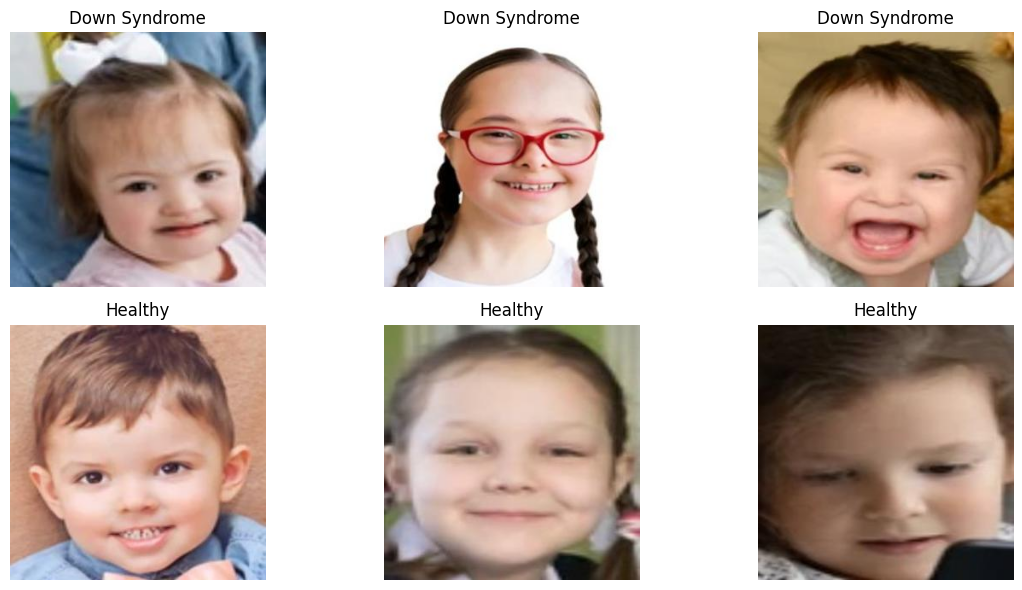

In [5]:
import matplotlib.pyplot as plt
from PIL import Image
import os
import random

plt.figure(figsize=(12, 6))

# Display 3 Down Syndrome images
for i in range(3):
    image_name = random.choice(down_images)
    image_path = os.path.join(down_path, image_name)

    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title("Down Syndrome")
    plt.axis("off")

# Display 3 Healthy images
for i in range(3):
    image_name = random.choice(healthy_images)
    image_path = os.path.join(healthy_path, image_name)

    image = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 4)
    plt.imshow(image)
    plt.title("Healthy")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
import os

print("Dataset folders:")
print(os.listdir(dataset_path))

print("\nDown Syndrome images:", len(down_images))
print("Healthy images:", len(healthy_images))

Dataset folders:
['labeling.xlsx', 'downSyndrome', 'healthy']

Down Syndrome images: 1500
Healthy images: 1499


In [7]:
import pandas as pd
import os

# Collect image paths and their corresponding labels
image_paths = []
labels = []

# Down Syndrome images
for image_name in down_images:
    image_paths.append(os.path.join(down_path, image_name))
    labels.append("Down Syndrome")

# Healthy images
for image_name in healthy_images:
    image_paths.append(os.path.join(healthy_path, image_name))
    labels.append("Healthy")

# Create a DataFrame
df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

# Display the first few rows
print(df.head())

# Check the class distribution
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nTotal images:", len(df))

                                            filepath          label
0  /content/drive/MyDrive/Down Syndrome ML Projec...  Down Syndrome
1  /content/drive/MyDrive/Down Syndrome ML Projec...  Down Syndrome
2  /content/drive/MyDrive/Down Syndrome ML Projec...  Down Syndrome
3  /content/drive/MyDrive/Down Syndrome ML Projec...  Down Syndrome
4  /content/drive/MyDrive/Down Syndrome ML Projec...  Down Syndrome

Class distribution:
label
Down Syndrome    1500
Healthy          1499
Name: count, dtype: int64

Total images: 2999


In [8]:
from sklearn.model_selection import train_test_split

# First, separate 15% for testing
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=df["label"]
)

# Then separate 15% of the complete dataset for validation
# This is approximately 17.65% of the remaining 85%.
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["label"].value_counts())

print("\nValidation class distribution:")
print(val_df["label"].value_counts())

print("\nTesting class distribution:")
print(test_df["label"].value_counts())

Training images: 2099
Validation images: 450
Testing images: 450

Training class distribution:
label
Down Syndrome    1050
Healthy          1049
Name: count, dtype: int64

Validation class distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64

Testing class distribution:
label
Healthy          225
Down Syndrome    225
Name: count, dtype: int64


In [9]:
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("Training-validation overlap:", len(train_paths & val_paths))
print("Training-testing overlap:", len(train_paths & test_paths))
print("Validation-testing overlap:", len(val_paths & test_paths))

Training-validation overlap: 0
Training-testing overlap: 0
Validation-testing overlap: 0


In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [11]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

In [12]:
val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [13]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

validation_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 2099 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.
Found 450 validated image filenames belonging to 2 classes.


In [14]:
print("Class mapping:", train_generator.class_indices)

images, labels = next(train_generator)

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

Class mapping: {'Down Syndrome': 0, 'Healthy': 1}

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [16]:
model = Sequential([
    # Input and first convolution block
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(224, 224, 3)
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Third convolution block
    Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten the feature maps
    Flatten(),

    # Fully connected layer
    Dense(128, activation="relu"),

    # Reduce overfitting
    Dropout(0.5),

    # Binary classification output
    Dense(1, activation="sigmoid")
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [18]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

In [19]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint_path = os.path.join(
    project_path,
    "best_cnn_model.keras"
)

checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("Checkpoint location:", checkpoint_path)

Checkpoint location: /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model.keras


In [ ]:
history = model.fit(
    train_generator,
    epochs=15,
    validation_data=validation_generator,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/15
 4/66 ━━━━━━━━━━━━━━━━━━━━ 6:02 6s/step - accuracy: 0.5540 - loss: 0.9498

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 8s/step - accuracy: 0.5466 - loss: 0.7530
Epoch 1: val_loss improved from None to 0.62518, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 623s 9s/step - accuracy: 0.5841 - loss: 0.6868 - val_accuracy: 0.6444 - val_loss: 0.6252
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 481ms/step - accuracy: 0.6625 - loss: 0.6007
Epoch 2: val_loss improved from 0.62518 to 0.57567, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 34s 515ms/step - accuracy: 0.6703 - loss: 0.6092 - val_accuracy: 0.7000 - val_loss: 0.5757
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.7058 - loss: 0.5811
Epoch 3: val_loss improved from 0.57567 to 

In [16]:
from tensorflow.keras.models import load_model
import os

checkpoint_path = os.path.join(
    project_path,
    "best_cnn_model.keras"
)

model = load_model(checkpoint_path)

print("Saved model loaded successfully!")

model.summary()

Saved model loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,507,269 (127.82 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,180 (85.21 MB)

In [17]:
print("Model compiled:", model.optimizer is not None)

print("Number of model parameters:", model.count_params())

Model compiled: True
Number of model parameters: 11169089


In [18]:
val_loss, val_accuracy = model.evaluate(
    validation_generator,
    verbose=1
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 165ms/step - accuracy: 0.7600 - loss: 0.5310
Validation Loss: 0.5310165286064148
Validation Accuracy: 0.7599999904632568


In [19]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

resume_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

resume_checkpoint = ModelCheckpoint(
    filepath=os.path.join(
        project_path,
        "best_cnn_model_resumed.keras"
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

In [20]:
resume_history = model.fit(
    train_generator,
    initial_epoch=5,
    epochs=6,
    validation_data=validation_generator,
    callbacks=[
        resume_early_stopping,
        resume_checkpoint
    ]
)

Epoch 6/6
47/66 ━━━━━━━━━━━━━━━━━━━━ 8s 468ms/step - accuracy: 0.7028 - loss: 0.5579

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 552ms/step - accuracy: 0.7112 - loss: 0.5506
Epoch 6: val_loss improved from None to 0.49374, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model_resumed.keras

Epoch 6: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model_resumed.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 46s 590ms/step - accuracy: 0.7346 - loss: 0.5325 - val_accuracy: 0.7711 - val_loss: 0.4937
Restoring model weights from the end of the best epoch: 6.


In [21]:
resume_history_2 = model.fit(
    train_generator,
    initial_epoch=6,
    epochs=15,
    validation_data=validation_generator,
    callbacks=[
        resume_early_stopping,
        resume_checkpoint
    ]
)

Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.7124 - loss: 0.5565
Epoch 7: val_loss did not improve from 0.49374
66/66 ━━━━━━━━━━━━━━━━━━━━ 32s 478ms/step - accuracy: 0.7037 - loss: 0.5588 - val_accuracy: 0.7489 - val_loss: 0.5292
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.7285 - loss: 0.5325
Epoch 8: val_loss did not improve from 0.49374
66/66 ━━━━━━━━━━━━━━━━━━━━ 31s 470ms/step - accuracy: 0.7384 - loss: 0.5180 - val_accuracy: 0.7622 - val_loss: 0.4946
Epoch 9/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.7486 - loss: 0.5082
Epoch 9: val_loss improved from 0.49374 to 0.48281, saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model_resumed.keras

Epoch 9: finished saving model to /content/drive/MyDrive/Down Syndrome ML Project/best_cnn_model_resumed.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 33s 505ms/step - accuracy: 0.7504 - loss: 0.5108 - val_accuracy: 0.7622 - val_loss: 0.4828
Epoch 10/15
66/66 ━━━━━━━━━━━━━━━━━━━

In [22]:
from tensorflow.keras.models import load_model
import os

best_model_path = os.path.join(
    project_path,
    "best_cnn_model_resumed.keras"
)

best_model = load_model(best_model_path)

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [23]:
test_loss, test_accuracy = best_model.evaluate(
    test_generator,
    verbose=1
)

print("\nTest Results")
print("----------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 97s 7s/step - accuracy: 0.8044 - loss: 0.4518

Test Results
----------------------
Test Loss: 0.451796293258667
Test Accuracy: 0.804444432258606


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [27]:
# Get actual labels and convert to NumPy array
y_true = np.array(test_generator.classes)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("\nClass mapping:")
print(test_generator.class_indices)

Actual labels shape: (450,)
Predicted labels shape: (450,)

Class mapping:
{'Down Syndrome': 0, 'Healthy': 1}


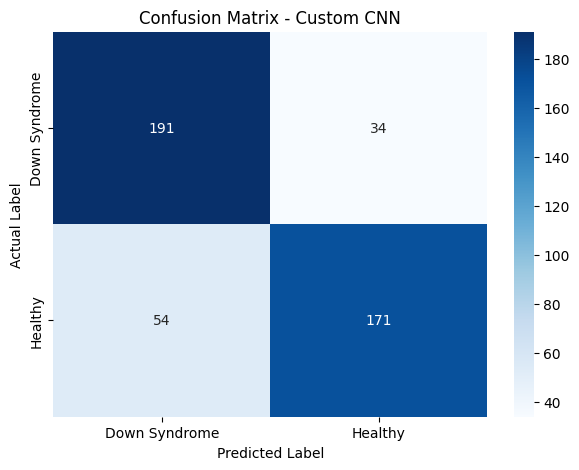

In [28]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Down Syndrome", "Healthy"],
    yticklabels=["Down Syndrome", "Healthy"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Custom CNN")

plt.show()

In [29]:
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Down Syndrome", "Healthy"],
    digits=4
))

               precision    recall  f1-score   support

Down Syndrome     0.7796    0.8489    0.8128       225
      Healthy     0.8341    0.7600    0.7953       225

     accuracy                         0.8044       450
    macro avg     0.8069    0.8044    0.8041       450
 weighted avg     0.8069    0.8044    0.8041       450



In [30]:
# Combine training history from recovered training

train_accuracy = (
    resume_history.history["accuracy"] +
    resume_history_2.history["accuracy"]
)

val_accuracy = (
    resume_history.history["val_accuracy"] +
    resume_history_2.history["val_accuracy"]
)

train_loss = (
    resume_history.history["loss"] +
    resume_history_2.history["loss"]
)

val_loss = (
    resume_history.history["val_loss"] +
    resume_history_2.history["val_loss"]
)

epochs_range = range(6, 6 + len(train_accuracy))

print("Available epochs:", len(train_accuracy))

Available epochs: 10


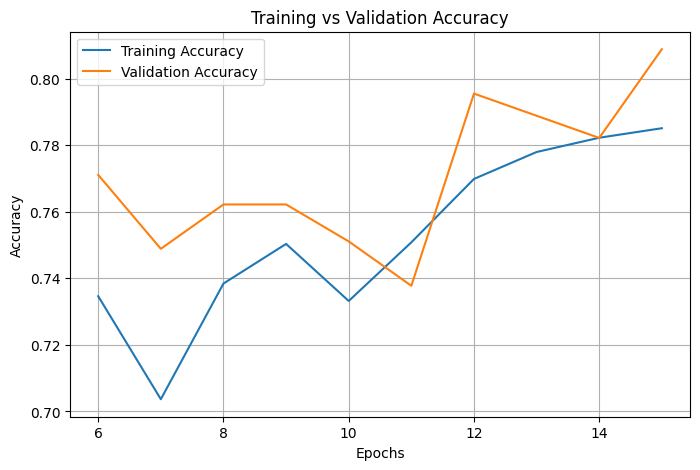

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accuracy,
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracy,
    label="Validation Accuracy"
)

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.show()

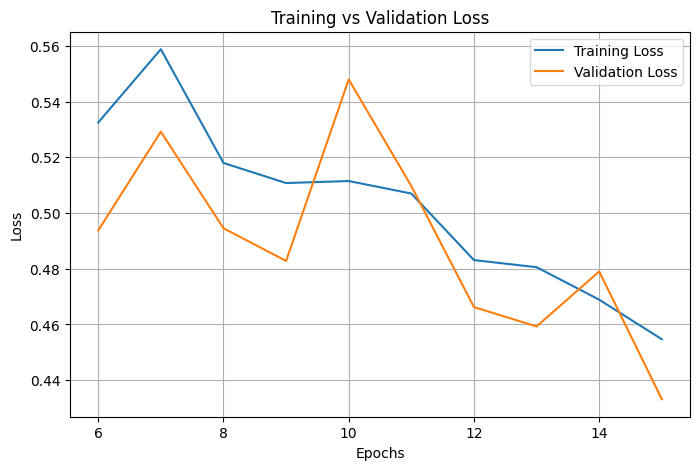

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [33]:
# Results recovered from original training logs (Epochs 1–5)

initial_train_accuracy = [
    0.5841, 0.6703, 0.6870, 0.7032, 0.7208
]

initial_val_accuracy = [
    0.6444, 0.7000, 0.7489, 0.7244, 0.7600
]

initial_train_loss = [
    0.6868, 0.6092, 0.5922, 0.5753, 0.5563
]

initial_val_loss = [
    0.6252, 0.5757, 0.5566, 0.5321, 0.5310
]

# Results from recovered training (Epochs 6–15)

train_accuracy = (
    initial_train_accuracy +
    resume_history.history["accuracy"] +
    resume_history_2.history["accuracy"]
)

val_accuracy = (
    initial_val_accuracy +
    resume_history.history["val_accuracy"] +
    resume_history_2.history["val_accuracy"]
)

train_loss = (
    initial_train_loss +
    resume_history.history["loss"] +
    resume_history_2.history["loss"]
)

val_loss = (
    initial_val_loss +
    resume_history.history["val_loss"] +
    resume_history_2.history["val_loss"]
)

epochs_range = range(1, 16)

print("Total epochs:", len(train_accuracy))
print("Training accuracy values:", len(train_accuracy))
print("Validation accuracy values:", len(val_accuracy))
print("Training loss values:", len(train_loss))
print("Validation loss values:", len(val_loss))

Total epochs: 15
Training accuracy values: 15
Validation accuracy values: 15
Training loss values: 15
Validation loss values: 15


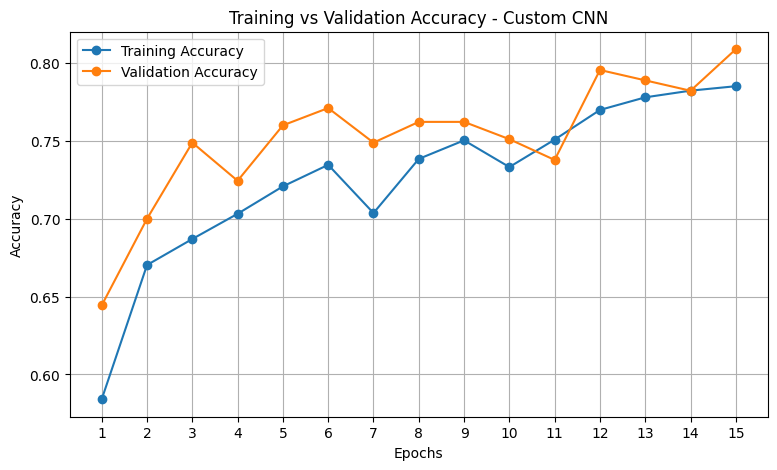

In [34]:
plt.figure(figsize=(9, 5))

plt.plot(epochs_range, train_accuracy,
         marker='o', label="Training Accuracy")

plt.plot(epochs_range, val_accuracy,
         marker='o', label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy - Custom CNN")

plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(project_path, "accuracy_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

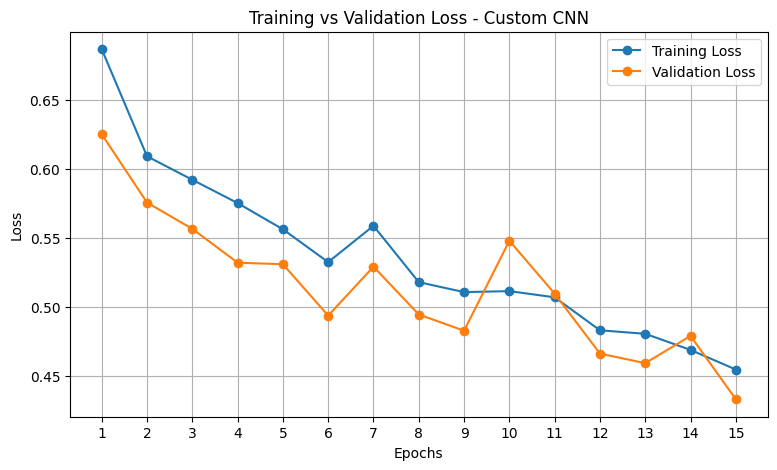

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(epochs_range, train_loss,
         marker='o', label="Training Loss")

plt.plot(epochs_range, val_loss,
         marker='o', label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss - Custom CNN")

plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(project_path, "loss_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
# Save dataset splits to Google Drive

train_df.to_csv(
    os.path.join(project_path, "train_split.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(project_path, "validation_split.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(project_path, "test_split.csv"),
    index=False
)

print("All dataset splits saved successfully!")

All dataset splits saved successfully!


In [37]:
print(os.listdir(project_path))

['down syndrome dataset', 'best_cnn_model.keras', 'best_cnn_model_resumed.keras', 'accuracy_graph.png', 'loss_graph.png', 'train_split.csv', 'validation_split.csv', 'test_split.csv']
